Marco Canal, Michael Duarte Gonçalves, Olivia Peter
May 15, 2026

# Exercise 2: forecasting the SP500 with Goyal-Welch indicators

Three target specifications are forecast one month ahead on the same chronological 60/15/25 split: log return, log price and the sign of the next-month return. For each target the notebook fits a multilayer perceptron, a Gaussian process and an LSTM, with the validation block used only for hyperparameter selection and the final model refit on train+validation before scoring on the held-out test block. Feature scaling and L1 feature selection (LassoCV for regression, L1 logistic for direction) use a TimeSeriesSplit inner CV on the training set only.

A sensitivity analysis then re-runs the full pipeline three more times, each time dropping every lag of one assigned Goyal-Welch indicator (dp, svar, bm), to check whether each one carries information out of sample.

## Part 1. Setup: environment, seeds, paths

We standardise the runtime (TensorFlow GPU detection, numpy/sklearn seeds), and
resolve the project directory so the same notebook runs on Colab and locally.


In [1]:
# Only run the !pip install on Colab. Locally we install from requirements.txt.
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    !pip install -q tensorflow scikit-learn pandas matplotlib

In [ ]:
import logging
import time
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel("ERROR")  # silence the LSTM retracing warning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel as C,
    DotProduct,
    Matern,
    RationalQuadratic,
    RBF,
    WhiteKernel,
)
from sklearn.linear_model import LassoCV, LogisticRegressionCV
from sklearn.metrics import accuracy_score, matthews_corrcoef, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, Input, LSTM
from tensorflow.keras.models import Sequential

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

logging.basicConfig(format="%(levelname)s: %(message)s", level=logging.INFO)
LOGGER = logging.getLogger("exercise_02")
VERBOSE_FITS = True

# Let TensorFlow handle device placement. We just toggle memory growth so a
# GPU session doesn't grab the whole card the moment the notebook opens.
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        LOGGER.debug("Could not set memory growth for %s", gpu)
LOGGER.info("TensorFlow %s, GPUs detected: %d", tf.__version__, len(gpus))

SEED = 7
np.random.seed(SEED)
tf.random.set_seed(SEED)
# Wall-clock fence, total runtime is logged in the final cell. The
# NN, LSTM and GP grids on a Colab T4 finish in a few minutes; on CPU
# the same grids take several hours, so the timer doubles as a
# sanity check that TensorFlow saw the GPU.
_T_START = time.perf_counter()


I0000 00:00:1778755085.032816  216077 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1778755085.828151  216077 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


INFO: TensorFlow 2.21.0, GPUs detected: 1


In [3]:
# Paths and a few global knobs. On Colab the project lives in Drive; locally
# we assume the notebook is run from inside the HW1 folder.
DRIVE_FOLDER = "ML4F_HW1"

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive", force_remount=False)
    PROJECT_DIR = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    # Walk up if launched from HW1/scripts/ so the same notebook works
    # from either HW1/ or HW1/scripts/.
    PROJECT_DIR = Path.cwd()
    if not (PROJECT_DIR / "data").is_dir() and (PROJECT_DIR.parent / "data").is_dir():
        PROJECT_DIR = PROJECT_DIR.parent

DATA_FILE = PROJECT_DIR / "data" / "goyal-welch2022Monthly.csv"
OUTPUT_DIR = PROJECT_DIR / "output" / "ex2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_FILE.exists():
    raise FileNotFoundError(DATA_FILE)

# Window, assigned indicators, lag counts and the chronological split.
START_DATE = "1927-01-01"
END_DATE = "2021-12-31"
ASSIGNED_INDICATORS = ["dp", "svar", "bm"]
N_LAGS_TARGET = 3
N_LAGS_EXOG = 3
P_TRAIN = 0.60
P_VAL = 0.15
P_TEST = 0.25

## Part 2. Build the monthly panel

We keep only the assigned variables, rebuild dividend-price and book-to-market the way the course helper does and add two convenience series on top: log price and log return. Direction is not stored here; it is derived from the next-month return inside `build_design` so the t+1 alignment lives in one place.

In [ ]:
# Load the Goyal-Welch monthly file and assemble the two natural target
# series (log price and log return) alongside the assigned indicators.
# The CSV stores `Index` with thousands separators, so we strip them
# before any arithmetic. `b/m` is renamed `bm` for tidier feature names.
LOGGER.info("Loading Goyal-Welch monthly data")
gw = pd.read_csv(DATA_FILE)

# yyyymm is an integer like 192701. Cast to str first so the format
# parser does not get confused by leading zeros at the millennium edge.
gw["Date"] = pd.to_datetime(gw["yyyymm"].astype(str), format="%Y%m")
gw = gw.set_index("Date").drop(columns="yyyymm")

# Strip comma separators ("1,234.56" -> 1234.56) before float-casting.
gw["Index"] = gw["Index"].str.replace(",", "", regex=False).astype(float)

# dp is the log dividend-price ratio (the classic GW indicator); bm is
# the book-to-market ratio renamed for cleaner column names downstream.
gw["dp"] = np.log(gw["D12"]) - np.log(gw["Index"])
gw["bm"] = gw["b/m"]
gw["log_price"] = np.log(gw["Index"])
gw["log_ret"] = gw["log_price"].diff()

# Restrict to the assignment window and drop any month with a missing
# value in the columns we actually use. We keep the underlying `Index`
# column in the panel for later inspection.
panel = gw.loc[
    START_DATE:END_DATE,
    ["Index", "log_price", "log_ret", *ASSIGNED_INDICATORS],
].dropna()

LOGGER.info("Panel after date restriction and NA removal: %d rows", len(panel))
panel.head()


INFO: Loading Goyal-Welch monthly data


INFO: Panel after date restriction and NA removal: 1140 rows


,Index,log_price,log_ret,dp,svar,bm
Date,,,,,,
1927-01-01,13.21,2.580974,-0.020975,-2.942374,0.000470,0.443706
1927-02-01,13.84,2.627563,0.046589,-2.979535,0.000287,0.428501
1927-03-01,13.93,2.634045,0.006482,-2.976535,0.000924,0.469765
1927-04-01,14.17,2.651127,0.017082,-2.984225,0.000603,0.456754
1927-05-01,14.91,2.702032,0.050905,-3.025963,0.000392,0.434783


## Part 3. Lags without look-ahead

Forward-shift the target by one period and lag every predictor accordingly.
The order matters: building lags before the date filter would leak the very
first observation of the held-out window into the training set.


In [ ]:
def build_design(panel: pd.DataFrame, target_kind: str) -> tuple[pd.DataFrame, pd.Series]:
    """Build lagged predictors and one aligned target series.

    The targets live at time t+1 (next month) and we predict them from
    information available at time t and earlier. `.shift(-1)` is the
    forward shift that produces the t+1 column; `.shift(lag - 1)` on a
    feature column gives lag `lag` once we line up with the target.

    For the direction target we cast the next-month-return sign to a
    float-valued 0/1 series first (so we can use `where` to preserve the
    NaN at the trailing edge) and then back to int after the final
    `dropna` has removed it.
    """
    if target_kind == "return":
        target = panel["log_ret"].shift(-1)
        own_lag_col = "log_ret"
    elif target_kind == "price":
        target = panel["log_price"].shift(-1)
        own_lag_col = "log_price"
    elif target_kind == "direction":
        next_return = panel["log_ret"].shift(-1)
        # `.astype(float).where(notna())` keeps NaNs as NaN; we cannot
        # cast directly to int because numpy ints have no NaN.
        target = (next_return > 0).astype(float).where(next_return.notna())
        own_lag_col = "log_ret"
    else:
        raise ValueError(f"Unknown target_kind: {target_kind}")

    columns = {}
    # Lags of the own target series. We use lag - 1 because the target
    # itself is already shifted by -1, so the "lag 1" feature is the
    # contemporaneous value at time t (the most recent observation).
    for lag in range(1, N_LAGS_TARGET + 1):
        columns[f"{own_lag_col}_lag{lag}"] = panel[own_lag_col].shift(lag - 1)
    # Lags of the assigned exogenous indicators, same convention.
    for variable in ASSIGNED_INDICATORS:
        for lag in range(1, N_LAGS_EXOG + 1):
            columns[f"{variable}_lag{lag}"] = panel[variable].shift(lag - 1)

    features = pd.DataFrame(columns, index=panel.index)
    design = pd.concat([features, target.rename("TARGET")], axis=1).dropna()
    y = design["TARGET"]
    if target_kind == "direction":
        y = y.astype(int)
    return design.drop(columns="TARGET"), y


def chronological_split(X: pd.DataFrame, y: pd.Series):
    """Split once in calendar order into train, validation and test blocks.

    Chronological -- never random. Any shuffle on a time series would
    leak future information into the training fold and inflate the
    score. The 60/15/25 split matches the assignment and matches the
    Exercise 3 baseline so the test sets coincide exactly.
    """
    n_obs = len(X)
    n_train = int(P_TRAIN * n_obs)
    n_val = int(P_VAL * n_obs)
    split = n_train + n_val
    return (
        X.iloc[:n_train],
        y.iloc[:n_train],
        X.iloc[n_train:split],
        y.iloc[n_train:split],
        X.iloc[split:],
        y.iloc[split:],
    )


## Part 4. Feature selection inside the training block

Selection is fit on training data only with a `TimeSeriesSplit` inner CV so no fold ever validates on data preceding its training window. LassoCV picks columns for return and price; for direction we use an L1 logistic regression on the same CV splits. If the selector returns fewer than three columns, a deterministic fallback keeps the top three by absolute coefficient.

In [ ]:
def select_features(X_tr: pd.DataFrame, y_tr: pd.Series, target_kind: str) -> list[str]:
    """Select features without letting validation or test data into the fit.

    L1-regularised model picks (Lasso for regression, L1-penalised
    logistic for direction). The inner CV is a `TimeSeriesSplit`,
    so that no fold ever validates on data that precedes the data it was trained on. Scaling is fitted on the
    training block only and re-used downstream by `standardise`.
    """
    scaler = StandardScaler().fit(X_tr)
    X_scaled = scaler.transform(X_tr)
    cv_splits = TimeSeriesSplit(n_splits=5)

    if target_kind == "direction":
        # `saga` is the only sklearn solver that supports L1 on the
        # logistic loss; max_iter is generous because the convergence
        # criterion can be slow at high `C` values on small samples.
        selector = LogisticRegressionCV(
            Cs=10,
            cv=cv_splits,
            penalty="l1",
            solver="saga",
            max_iter=10000,
            scoring="accuracy",
            random_state=SEED,
        ).fit(X_scaled, y_tr)
        coefs = np.abs(selector.coef_).ravel()
    else:
        selector = LassoCV(
            cv=cv_splits,
            max_iter=20000,
            random_state=SEED,
        ).fit(X_scaled, y_tr)
        coefs = np.abs(selector.coef_)

    # Anything below 1e-8 is numerical zero from the L1 step.
    selected = [col for col, weight in zip(X_tr.columns, coefs) if weight > 1e-8]
    if len(selected) >= 3:
        return selected

    # Fallback when the selector shrinks too aggressively: fall back to
    # the three largest-coefficient features. Deterministic and still
    # only uses the training set, so no leakage is introduced.
    order = np.argsort(coefs)[::-1]
    return [X_tr.columns[i] for i in order[:3]]


## Part 5. Scores and the model builders

Lab-defined NRMSE, the small `standardise` helper that reuses the training
scaler for validation and test, and the per-task `evaluate` that returns the
right metrics dictionary for regression vs. classification.


In [ ]:
def nrmse(y_true, y_pred) -> float:
    """Course PyLab NRMSE convention for regression targets.

    Defined as `sqrt(MSE / mean(sum((y - mean)^2)))`. Note that this is
    NOT the sklearn definition (which divides by range or by mean). We use here normalization seen in class
    so that `pcorrect = 100 * (1 - NRMSE)` lands in a 0-100 band.
    """
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    # `np.mean(np.sum(...))` mirrors the lab notation; on a 1-D array
    # the mean of a scalar is the scalar itself, so the result equals
    # `((y - mean)**2).sum()`.
    denominator = np.mean(np.sum((y_true - y_true.mean()) ** 2))
    if np.isclose(denominator, 0.0):
        raise ValueError("target has zero variance")
    return float(np.sqrt(mean_squared_error(y_true, y_pred) / denominator))


def pcorrect(y_true, y_pred) -> float:
    # Lab convenience metric. Not a probability of a correct sign call.
    return 100.0 * (1.0 - nrmse(y_true, y_pred))


def standardise(X_tr, X_va, X_te):
    """Fit the scaler on training data and reuse it for later blocks.

    Fitting the scaler on the full panel would peek at validation and
    test moments -- a textbook leak. We fit on X_tr only and apply the
    fitted transform to X_va and X_te.
    """
    scaler = StandardScaler().fit(X_tr)
    return scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te), scaler


def evaluate(y_true, y_pred, classification: bool) -> dict:
    """One-stop dict of test-set metrics, dispatching on target type."""
    if classification:
        # MCC distinguishes a "always majority" classifier (MCC = 0)
        # from one that actually uses the features (MCC != 0), even when
        # raw accuracy looks identical.
        return {
            "accuracy": accuracy_score(y_true, y_pred),
            "MCC": matthews_corrcoef(y_true, y_pred),
            "n": int(len(y_true)),
        }
    score = nrmse(y_true, y_pred)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "NRMSE": score,
        "pcorrect": 100.0 * (1.0 - score),
        "n": int(len(y_true)),
    }


### Neural network

Width, depth and activation are tuned on the validation block, then the winner is refit on train+validation. The grid is 4 hidden-layer shapes x 2 activations = 8 configurations, MLPRegressor for regression and MLPClassifier for direction.

In [8]:
def fit_nn(X_tr, y_tr, X_va, y_va, classification: bool):
    """Tune width, depth and activation on validation, then refit.

    Small explicit grid (eight architectures): the validation block is
    only 170 rows, so a Random Search or Bayesian search would just add
    noise. The final fit is on train+validation combined.
    """
    grid = [
        {"hidden_layer_sizes": hls, "activation": activation}
        for hls in [(64,), (128,), (64, 64), (128, 64)]
        for activation in ["relu", "tanh"]
    ]
    estimator_cls = MLPClassifier if classification else MLPRegressor
    best = None
    # Sentinel values that the first iteration always beats.
    best_score = -np.inf if classification else np.inf

    for k, params in enumerate(grid):
        # alpha is sklearn's L2 weight; 1e-3 is a mild prior that helps
        # the validation NRMSE settle on the smaller architectures.
        model = estimator_cls(
            max_iter=2000,
            alpha=1e-3,
            solver="adam",
            random_state=SEED,
            **params,
        ).fit(X_tr, y_tr)
        score = (
            accuracy_score(y_va, model.predict(X_va))
            if classification
            else nrmse(y_va, model.predict(X_va))
        )
        better = score > best_score if classification else score < best_score
        if better:
            best_score = score
            best = params
        if VERBOSE_FITS:
            LOGGER.info("NN[%d/%d] %s validation score %.4f", k + 1, len(grid), params, score)

    LOGGER.info("NN best validation score for current target: %.4f", best_score)
    # Refit the chosen architecture on train+validation combined; this
    # is the model that gets scored on the held-out test block.
    X_full = np.vstack([X_tr, X_va])
    y_full = np.concatenate([np.asarray(y_tr), np.asarray(y_va)])
    final = estimator_cls(
        max_iter=2000,
        alpha=1e-3,
        solver="adam",
        random_state=SEED,
        **best,
    ).fit(X_full, y_full)
    return final, best


### Gaussian process

We try four kernels (RBF, Matern with nu=2.5, RationalQuadratic and a custom non-stationary additive RBF + Linear + WhiteNoise), pick the one with the lowest validation NRMSE and refit on train+validation. The custom additive kernel is the natural fit for the price target, which is essentially a random walk with drift.

In [ ]:
def fit_gp(X_tr, y_tr, X_va, y_va):
    """Tune the GP kernel on validation, then refit on train plus validation.

    Four kernels: RBF, Matern(5/2), RationalQuadratic, and a custom
    additive RBF+Linear that gives the GP an explicit drift term
    (useful for the log-price target, which is a near-random-walk).
    Each kernel has its own `WhiteKernel` for an observation-noise term;
    `alpha=1e-6` is the additional jitter sklearn applies for numerical
    stability of the Cholesky decomposition.
    """
    kernels = {
        "RBF": C(1.0) * RBF(1.0) + WhiteKernel(noise_level=1e-2),
        "Matern_2.5": C(1.0) * Matern(length_scale=1.0, nu=2.5)
        + WhiteKernel(noise_level=1e-2),
        "RatQuad": C(1.0) * RationalQuadratic(length_scale=1.0, alpha=1.0)
        + WhiteKernel(noise_level=1e-2),
        "custom_RBF+Lin": (C(1.0) * RBF(1.0))
        + (C(1.0) * DotProduct())
        + WhiteKernel(noise_level=1e-2),
    }
    best_name = None
    best_model = None
    best_score = np.inf  # NRMSE is a loss; smaller is better.

    for k, (name, kernel) in enumerate(kernels.items()):
        # `n_restarts_optimizer=2` gives the L-BFGS hyper-fit two extra
        # starts from random points, multiple restarts protect against
        # the marginal-likelihood being multi-modal in kernel space.
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=1e-6,
            normalize_y=True,
            n_restarts_optimizer=2,
            random_state=SEED,
        ).fit(X_tr, y_tr)
        score = nrmse(y_va, gp.predict(X_va))
        if score < best_score:
            best_name = name
            best_model = gp
            best_score = score
        if VERBOSE_FITS:
            LOGGER.info("GP[%d/%d] %s validation score %.4f", k + 1, len(kernels), name, score)

    LOGGER.info("GP best validation score for current target: %.4f", best_score)
    # Refit the winning kernel on train+validation. Note that we reuse
    # `best_model.kernel_` (the fitted kernel with optimised
    # hyperparameters); the optimiser will re-tune them on the larger
    # block.
    X_full = np.vstack([X_tr, X_va])
    y_full = np.concatenate([np.asarray(y_tr), np.asarray(y_va)])
    final = GaussianProcessRegressor(
        kernel=best_model.kernel_,
        alpha=1e-6,
        normalize_y=True,
        n_restarts_optimizer=2,
        random_state=SEED,
    ).fit(X_full, y_full)
    return final, {"kernel": best_name}


### LSTM

The LSTM reads short rolling windows so the recent path of the predictors can matter on top of the lagged columns. To keep every test forecast usable, validation and test windows are seeded with the last few rows of the previous block; the grid sweeps units, depth and timestep length.

In [10]:
def to_lstm_tensor(X: np.ndarray, y: np.ndarray, timesteps: int):
    """Create rolling LSTM windows from a two-dimensional design matrix."""
    if X.shape[0] < timesteps:
        return np.empty((0, timesteps, X.shape[1])), np.empty((0,))
    X_seq = []
    y_seq = []
    for index in range(timesteps - 1, X.shape[0]):
        X_seq.append(X[index - timesteps + 1 : index + 1, :])
        y_seq.append(y[index])
    return np.array(X_seq), np.array(y_seq)


def build_lstm(input_shape, units: int, layers: int, classification: bool) -> Sequential:
    """Construct the same LSTM architecture used for tuning and final fitting."""
    model = Sequential([Input(shape=input_shape)])
    for layer in range(layers):
        return_sequences = layer < layers - 1
        model.add(LSTM(units, return_sequences=return_sequences))
        model.add(Dropout(0.1))
    if classification:
        model.add(Dense(1, activation="sigmoid"))
        model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
    else:
        model.add(Dense(1))
        model.compile(loss="mse", optimizer="adam")
    return model


def validation_lstm_tensor(X_tr, y_tr, X_va, y_va, timesteps: int):
    """Seed validation windows with the last training rows."""
    X_seeded = np.vstack([X_tr[-(timesteps - 1) :], X_va])
    y_seeded = np.concatenate([np.asarray(y_tr)[-(timesteps - 1) :], np.asarray(y_va)])
    X_val, y_val = to_lstm_tensor(X_seeded, y_seeded, timesteps)
    return X_val[-len(y_va) :], y_val[-len(y_va) :]


def fit_lstm(X_tr, y_tr, X_va, y_va, classification: bool):
    """Tune units, layers and sequence length on validation, then refit."""
    grid = [
        {"units": 32, "layers": 1, "timesteps": 6},
        {"units": 64, "layers": 1, "timesteps": 6},
        {"units": 32, "layers": 2, "timesteps": 6},
        {"units": 64, "layers": 2, "timesteps": 12},
    ]
    best = None
    best_score = -np.inf if classification else np.inf

    for k, params in enumerate(grid):
        timesteps = params["timesteps"]
        X_train_3d, y_train_3d = to_lstm_tensor(X_tr, np.asarray(y_tr), timesteps)
        X_val_3d, y_val_3d = validation_lstm_tensor(X_tr, y_tr, X_va, y_va, timesteps)

        tf.keras.utils.set_random_seed(SEED)
        model = build_lstm(
            (timesteps, X_tr.shape[1]),
            params["units"],
            params["layers"],
            classification,
        )
        early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
        model.fit(
            X_train_3d,
            y_train_3d,
            epochs=200,
            batch_size=32,
            verbose=0,
            validation_split=0.1,
            callbacks=[early_stop],
        )
        raw_pred = model.predict(X_val_3d, verbose=0).ravel()
        preds = (raw_pred > 0.5).astype(int) if classification else raw_pred
        score = accuracy_score(y_val_3d, preds) if classification else nrmse(y_val_3d, preds)
        better = score > best_score if classification else score < best_score
        if better:
            best_score = score
            best = params
        if VERBOSE_FITS:
            LOGGER.info("LSTM[%d/%d] %s validation score %.4f", k + 1, len(grid), params, score)

    LOGGER.info("LSTM best validation score for current target: %.4f", best_score)
    timesteps = best["timesteps"]
    X_full = np.vstack([X_tr, X_va])
    y_full = np.concatenate([np.asarray(y_tr), np.asarray(y_va)])
    X_full_3d, y_full_3d = to_lstm_tensor(X_full, y_full, timesteps)

    tf.keras.utils.set_random_seed(SEED)
    final = build_lstm(
        (timesteps, X_tr.shape[1]),
        best["units"],
        best["layers"],
        classification,
    )
    early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    final.fit(
        X_full_3d,
        y_full_3d,
        epochs=200,
        batch_size=32,
        verbose=0,
        validation_split=0.1,
        callbacks=[early_stop],
    )
    return final, best


def predict_lstm(
    model,
    X_tr_full: np.ndarray,
    X_te: np.ndarray,
    timesteps: int,
    classification: bool,
):
    """Predict the test block without dropping the first test observations."""
    X_augmented = np.vstack([X_tr_full[-(timesteps - 1) :], X_te])
    windows = []
    for index in range(timesteps - 1, len(X_augmented)):
        windows.append(X_augmented[index - timesteps + 1 : index + 1, :])
    X_seq = np.array(windows)[-X_te.shape[0] :]
    raw = model.predict(X_seq, verbose=0).ravel()
    return (raw > 0.5).astype(int) if classification else raw

## Part 6. One target, end to end

Single function that runs a full target: select features, scale, tune NN/GP/LSTM
on validation, refit on train+validation, score on test, and stack a naive
baseline row alongside the three trained models.


In [11]:
def run_target(target_kind: str, drop_var: str | None = None):
    """Run feature selection, model fitting and test evaluation for one target."""
    label = target_kind if drop_var is None else f"{target_kind}/drop {drop_var}"
    LOGGER.info("Running target: %s", label)
    classification = target_kind == "direction"

    X, y = build_design(panel, target_kind)
    if drop_var is not None:
        drop_columns = [col for col in X.columns if col.startswith(f"{drop_var}_lag")]
        X = X.drop(columns=drop_columns)

    X_tr, y_tr, X_va, y_va, X_te, y_te = chronological_split(X, y)
    keep = select_features(X_tr, y_tr, target_kind)
    LOGGER.info("Keeping %d features for %s", len(keep), label)

    X_tr = X_tr[keep].values
    X_va = X_va[keep].values
    X_te = X_te[keep].values
    X_tr_s, X_va_s, X_te_s, _ = standardise(X_tr, X_va, X_te)

    rows = []
    predictions = {}

    nn_model, nn_best = fit_nn(X_tr_s, y_tr, X_va_s, y_va, classification)
    pred_nn = nn_model.predict(X_te_s)
    rows.append(
        {
            "target": target_kind,
            "model": "NN",
            "params": str(nn_best),
            **evaluate(y_te, pred_nn, classification),
        }
    )
    predictions["NN"] = pred_nn

    if classification:
        gp_model, gp_best = fit_gp(
            X_tr_s,
            y_tr.astype(float),
            X_va_s,
            y_va.astype(float),
        )
        pred_gp = (gp_model.predict(X_te_s) > 0.5).astype(int)
    else:
        gp_model, gp_best = fit_gp(X_tr_s, y_tr, X_va_s, y_va)
        pred_gp = gp_model.predict(X_te_s)
    rows.append(
        {
            "target": target_kind,
            "model": "GP",
            "params": str(gp_best),
            **evaluate(y_te, pred_gp, classification),
        }
    )
    predictions["GP"] = pred_gp

    lstm_model, lstm_best = fit_lstm(X_tr_s, y_tr, X_va_s, y_va, classification)
    X_train_full = np.vstack([X_tr_s, X_va_s])
    pred_lstm = predict_lstm(
        lstm_model,
        X_train_full,
        X_te_s,
        lstm_best["timesteps"],
        classification,
    )
    rows.append(
        {
            "target": target_kind,
            "model": "LSTM",
            "params": str(lstm_best),
            **evaluate(y_te, pred_lstm, classification),
        }
    )
    predictions["LSTM"] = pred_lstm

    if classification:
        baseline = np.full(len(y_te), int(y_tr.mean() >= 0.5))
        baseline_name = "BaselineMajority"
    else:
        baseline = np.full(len(y_te), float(y_tr.mean()))
        baseline_name = "BaselineMean"
    rows.append(
        {
            "target": target_kind,
            "model": baseline_name,
            "params": "{}",
            **evaluate(y_te, baseline, classification),
        }
    )
    predictions[baseline_name] = baseline

    return rows, predictions, y_te, keep

## Part 7. The main forecasting run

All three targets are run once on the full assigned feature set; the resulting metrics DataFrame is what the report tables read from. Hyperparameter details (kernel name, layer sizes) land in the params column and are kept out of the main writeup tables.

In [12]:
%%time
# Main forecasting run: three targets, each going through the full
# select-features -> tune -> refit -> score pipeline. We collect rows
# for the metrics table, the test-block predictions for the plots,
# the realised test series, and the selected feature lists.
LOGGER.info("Running main target specifications")
all_rows = []
all_preds = {}
all_truths = {}
all_features = {}

for target_kind in ["return", "price", "direction"]:
    rows, preds, y_te, keep = run_target(target_kind)
    all_rows.extend(rows)
    all_preds[target_kind] = preds
    all_truths[target_kind] = y_te
    all_features[target_kind] = keep

metrics_df = pd.DataFrame(all_rows)
metrics_df


INFO: Running main target specifications


INFO: Running target: return


INFO: Keeping 3 features for return


INFO: NN[1/8] {'hidden_layer_sizes': (64,), 'activation': 'relu'} validation score 0.0923


INFO: NN[2/8] {'hidden_layer_sizes': (64,), 'activation': 'tanh'} validation score 0.0912


...

INFO: LSTM[3/4] {'units': 32, 'layers': 2, 'timesteps': 6} validation score 0.6529


INFO: LSTM[4/4] {'units': 64, 'layers': 2, 'timesteps': 12} validation score 0.6118


INFO: LSTM best validation score for current target: 0.6529


CPU times: user 1h 4min 24s, sys: 36.1 s, total: 1h 5min
Wall time: 3min 18s


,target,model,params,RMSE,NRMSE,pcorrect,n,accuracy,MCC
0,return,NN,"{'hidden_layer_sizes': (128, 64), 'activation'...",0.052636,0.070104,92.989620,285,NaN,NaN
1,return,GP,{'kernel': 'RBF'},0.044476,0.059235,94.076511,285,NaN,NaN
2,return,LSTM,"{'units': 64, 'layers': 1, 'timesteps': 6}",0.047215,0.062883,93.711708,285,NaN,NaN
3,return,BaselineMean,{},0.044502,0.059270,94.073013,285,NaN,NaN
4,price,NN,"{'hidden_layer_sizes': (64,), 'activation': 'r...",0.327208,0.046613,95.338717,285,NaN,NaN
5,price,GP,{'kernel': 'custom_RBF+Lin'},0.079482,0.011323,98.867724,285,NaN,NaN
6,price,LSTM,"{'units': 64, 'layers': 1, 'timesteps': 6}",1.242283,0.176971,82.302911,285,NaN,NaN
7,price,BaselineMean,{},3.819839,0.544160,45.584038,285,NaN,NaN
8,direction,NN,"{'hidden_layer_sizes': (128,), 'activation': '...",NaN,NaN,NaN,285,0.607018,-0.057137
9,direction,GP,{'kernel': 'RatQuad'},NaN,NaN,NaN,285,0.624561,0.000000


## Part 8. Sensitivity checks

For each assigned predictor the whole pipeline is repeated with every lag of that variable removed before feature selection runs. That is stricter than zeroing a single column: the variable cannot come back through the selector. The question is whether the model actually needs dp, svar or bm, or whether the main forecast rides on the target's own lags.

In [13]:
%%time
# Sensitivity analysis: drop each assigned indicator in turn (all of
# its lags) and rerun the whole pipeline. Differences from the main run
# isolate the marginal contribution of each indicator. Note this is a
# full rerun of feature selection too, so the kept-feature set shifts.
LOGGER.info("Running sensitivity analysis")
sens_rows = []
for drop_var in ASSIGNED_INDICATORS:
    for target_kind in ["return", "price", "direction"]:
        rows, _, _, _ = run_target(target_kind, drop_var=drop_var)
        for row in rows:
            row["dropped"] = drop_var
            sens_rows.append(row)

sens_df = pd.DataFrame(sens_rows)
sens_df


INFO: Running sensitivity analysis


INFO: Running target: return/drop dp


INFO: Keeping 3 features for return/drop dp


INFO: NN[1/8] {'hidden_layer_sizes': (64,), 'activation': 'relu'} validation score 0.0803


INFO: NN[2/8] {'hidden_layer_sizes': (64,), 'activation': 'tanh'} validation score 0.1429


...

INFO: LSTM[3/4] {'units': 32, 'layers': 2, 'timesteps': 6} validation score 0.6529


INFO: LSTM[4/4] {'units': 64, 'layers': 2, 'timesteps': 12} validation score 0.6529


INFO: LSTM best validation score for current target: 0.6529


CPU times: user 3h 30min 58s, sys: 1min 48s, total: 3h 32min 47s
Wall time: 10min 16s


,target,model,params,RMSE,NRMSE,pcorrect,n,dropped,accuracy,MCC
0,return,NN,"{'hidden_layer_sizes': (128,), 'activation': '...",0.059246,0.078907,92.109284,285,dp,NaN,NaN
1,return,GP,{'kernel': 'RBF'},0.044476,0.059235,94.076511,285,dp,NaN,NaN
2,return,LSTM,"{'units': 64, 'layers': 1, 'timesteps': 6}",0.048010,0.063942,93.605783,285,dp,NaN,NaN
3,return,BaselineMean,{},0.044502,0.059270,94.073013,285,dp,NaN,NaN
4,price,NN,"{'hidden_layer_sizes': (128, 64), 'activation'...",0.149964,0.021363,97.863671,285,dp,NaN,NaN
5,price,GP,{'kernel': 'custom_RBF+Lin'},0.094843,0.013511,98.648906,285,dp,NaN,NaN
6,price,LSTM,"{'units': 64, 'layers': 1, 'timesteps': 6}",1.034692,0.147398,85.260173,285,dp,NaN,NaN
7,price,BaselineMean,{},3.819839,0.544160,45.584038,285,dp,NaN,NaN
8,direction,NN,"{'hidden_layer_sizes': (64,), 'activation': 'r...",NaN,NaN,NaN,285,dp,0.624561,0.000000
9,direction,GP,{'kernel': 'RatQuad'},NaN,NaN,NaN,285,dp,0.624561,0.000000


## Part 9. Save the report files

This cell writes everything `solution.tex` reads back: the metrics tables, the sensitivity tables, the prediction CSVs, the list of selected features and the figures. After a clean run, Exercise 2 is reproducible from the saved files alone, without having to re-execute the notebook.

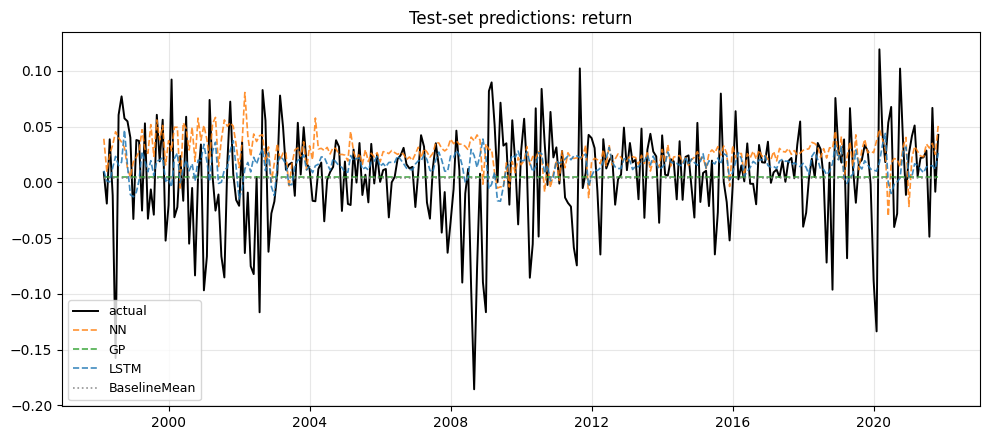

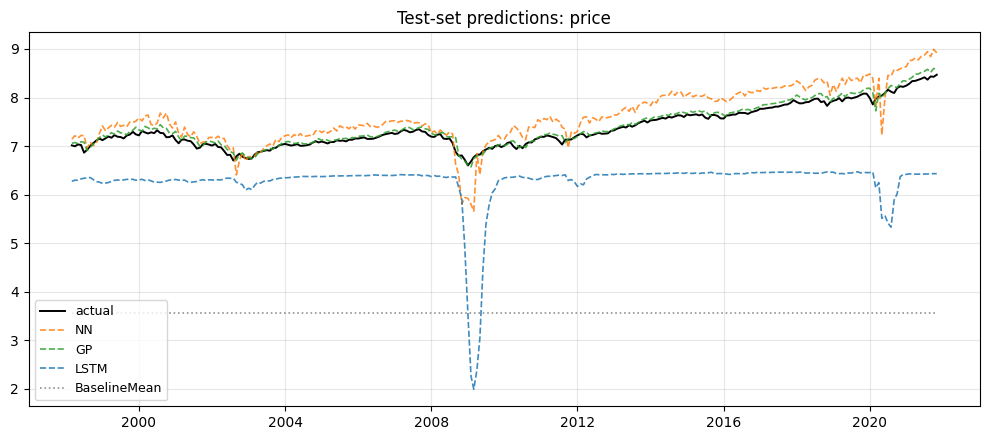

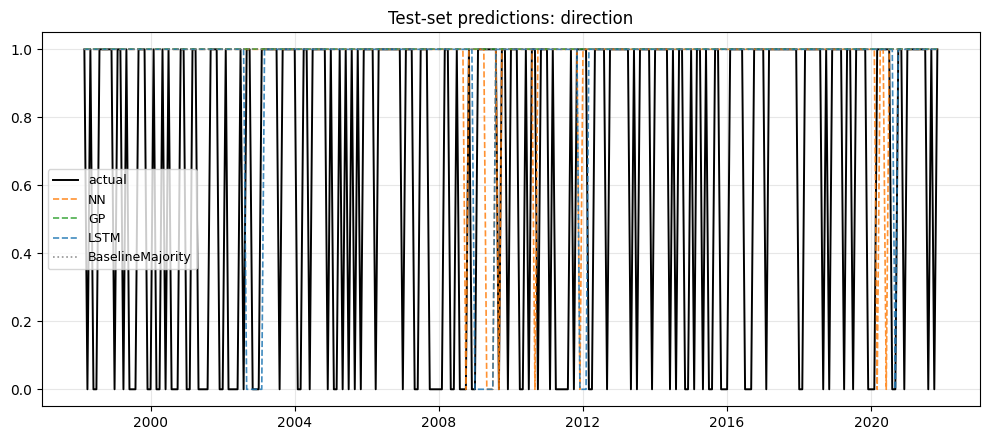

INFO: Artifacts written to /home/michael/Desktop/BSE_DSM/ThirdTerm/MachineLearning_Finance/ProblemSets/ML4F/HW1/output/ex2


INFO: Exercise 2 finished in 817.0 s wall time


In [14]:
def df_to_latex(df: pd.DataFrame, name: str, caption: str, filename: str | None = None) -> None:
    """Write a DataFrame as a LaTeX table fragment.

    ``name`` becomes the ``\\label{tab:<name>}`` for cross-references in the
    report; ``filename`` (defaulting to ``name``) is the basename of the
    .tex file written to ``OUTPUT_DIR``.
    """
    tex = df.to_latex(
        index=False,
        float_format="{:.4f}".format,
        column_format="l" * len(df.columns),
        escape=False,
    )
    output = (
        "\\begin{table}[H]\n\\centering\n\\small\n"
        + tex
        + "\\caption{"
        + caption
        + "}\n\\label{tab:"
        + name
        + "}\n\\end{table}\n"
    )
    (OUTPUT_DIR / f"{filename or name}.tex").write_text(output)


model_registry = metrics_df[["target", "model", "params"]].copy()
model_registry.to_csv(OUTPUT_DIR / "12_ex2_model_registry.csv", index=False)
metrics_df.to_csv(OUTPUT_DIR / "02_ex2_metrics.csv", index=False)
df_to_latex(
    metrics_df,
    "ex2_metrics",
    "Test-set forecast performance for each (target, model) combination.",
    filename="03_ex2_metrics",
)

sens_df.to_csv(OUTPUT_DIR / "04_ex2_sensitivity.csv", index=False)
df_to_latex(
    sens_df,
    "ex2_sensitivity",
    "Sensitivity analysis: each row is the test-set performance when all lags "
    "of the indicated variable are removed from the feature set.",
    filename="05_ex2_sensitivity",
)

PRED_FILES = {
    "return": "06_ex2_pred_return.csv",
    "price": "08_ex2_pred_price.csv",
    "direction": "10_ex2_pred_direction.csv",
}
FIG_FILES = {
    "return": "07_ex2_fig_return.pdf",
    "price": "09_ex2_fig_price.pdf",
    "direction": "11_ex2_fig_direction.pdf",
}
STYLE = {
    "NN": ("--", "tab:orange"),
    "GP": ("--", "tab:green"),
    "LSTM": ("--", "tab:blue"),
    "BaselineMean": (":", "grey"),
    "BaselineMajority": (":", "grey"),
}

for target_kind, preds in all_preds.items():
    y_te = all_truths[target_kind]
    output = pd.DataFrame({"y_true": y_te.values}, index=y_te.index)
    for model_name, prediction in preds.items():
        output[f"pred_{model_name}"] = np.asarray(prediction)
    output.to_csv(OUTPUT_DIR / PRED_FILES[target_kind])

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(y_te.index, y_te.values, label="actual", color="black", linewidth=1.4)
    for model_name, prediction in preds.items():
        linestyle, colour = STYLE.get(model_name, ("--", "tab:purple"))
        ax.plot(
            y_te.index,
            np.asarray(prediction),
            label=model_name,
            linestyle=linestyle,
            color=colour,
            alpha=0.85,
            linewidth=1.2,
        )
    ax.set_title(f"Test-set predictions: {target_kind}")
    ax.legend(loc="best", fontsize=9)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / FIG_FILES[target_kind], bbox_inches="tight")
    plt.show()
    plt.close(fig)

feature_selection = pd.DataFrame(
    {target: pd.Series(cols) for target, cols in all_features.items()}
)
feature_selection.to_csv(OUTPUT_DIR / "01_ex2_feature_selection.csv", index=False)
LOGGER.info("Artifacts written to %s", OUTPUT_DIR)
LOGGER.info("Exercise 2 finished in %.1f s wall time", time.perf_counter() - _T_START)


## Part 10. Where the files go

The script just drops CSV, TeX and figure artefacts into `output/`.